# Expérience 5 — fidélité de reconstruction sur CAMUS (RTX 4060 Ti)

Ce notebook reconstruit des coupes d'échocardiographie 2D (jeu CAMUS, images `camus_64`) avec un `AutoencoderKL` de MONAI. Il reprend la graine, le découpage par patient et la normalisation des expériences 1 à 4. L'expérience 4 a validé les seuils de qualité (MSE test 0,00343, MSE cœur 0,00518, SSIM 0,787, PSNR 25,12 dB, Spearman 0,943 dans `artifacts/results_exp4.json`). Ici la priorité change : la fidélité à l'image échographique d'origine passe devant le temps de calcul.

Cinq leviers :

1. **Capacité.** Canaux `(32, 64, 128, 256)`, deux blocs résiduels par échelle, attention au goulot 8×8. Le code latent reste 8×8×8.
2. **Perte de netteté.** MSE pondérée, L1 pondérée, SSIM et L1 des gradients spatiaux. Le cœur pèse `W = 1 + 3,5 · 1(label > 0)`.
3. **Latent plus souple.** β monte jusqu'à `2×10⁻⁵` en 15 époques, et γ de l'AR-VAE passe à 0,03. L'axe `z0` doit garder un Spearman supérieur à 0,85 avec l'aire du ventricule gauche.
4. **Cent époques.** AdamW à `10⁻³` et un cosinus jusqu'à `10⁻⁵`. Le checkpoint est la plus faible perte de reconstruction de validation une fois le warmup terminé.
5. **FP32, sans synchronisation par lot.** Pas de précision mixte ni de TF32. Les images d'entraînement et de validation sont préchargées en VRAM. Les moyennes d'époque ne reviennent sur le CPU qu'une fois par époque, et le fichier `.pth` n'est écrit qu'à la fin.

La barre qui interrompt le notebook est le dépassement de l'expérience 4 sur la MSE globale, la MSE cœur, le SSIM et le PSNR, avec Spearman > 0,85.


In [1]:
%matplotlib inline

import json
import os
import random
import time
import zipfile
from collections import Counter
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from monai.data import DataLoader
from monai.losses import SSIMLoss
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL
from monai.utils import set_determinism
from scipy.stats import pearsonr, spearmanr
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch {torch.__version__}  |  MONAI {monai.__version__}  |  NumPy {np.__version__}")


PyTorch 2.7.0+cu128  |  MONAI 1.5.2  |  NumPy 2.5.3


In [2]:
SEED = 12345


def enable_fast_cuda():
    # FP32 pur : TF32 réduit la mantisse des convolutions et des produits matriciels.
    # set_determinism force benchmark=False. On le rétablit ensuite, la taille 64×64 est fixe.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision("highest")
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    set_determinism(seed=seed)
    enable_fast_cuda()


set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA est indisponible dans cet interpréteur "
        f"(PyTorch {torch.__version__}). Relancer le notebook avec le Python "
        "qui fournit un wheel +cu128 ou +cu124."
    )

device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
gpu_props = torch.cuda.get_device_properties(0)
vram_total = gpu_props.total_memory
vram_allocated = torch.cuda.memory_allocated(0)
print(f"Périphérique : {device}")
print(f"GPU : {gpu_name}")
print(f"VRAM totale : {vram_total / 1024 ** 3:.2f} Go")
print(f"VRAM allouée : {vram_allocated / 1024 ** 2:.1f} Mo")
print(f"PyTorch CUDA : {torch.version.cuda}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "exp5_vae_best.pth"


Périphérique : cuda
GPU : NVIDIA GeForce RTX 4060 Ti
VRAM totale : 8.00 Go
VRAM allouée : 0.0 Mo
PyTorch CUDA : 12.8


## 1. Audit et préparation des données

Les images restent hors du dépôt. Le dossier est `CAMUS_DATA_ROOT` s'il est défini, sinon `../camus_64`, sinon `data/camus_64`. Si aucun des trois n'existe, l'archive du cours est téléchargée.


In [3]:
if os.environ.get("CAMUS_DATA_ROOT"):
    root = Path(os.environ["CAMUS_DATA_ROOT"]).expanduser().resolve()
    data_dir = root if root.name.startswith("camus_") else root / "camus_64"
elif (Path("..") / "camus_64").resolve().is_dir():
    data_dir = (Path("..") / "camus_64").resolve()
elif (Path("data") / "camus_64").resolve().is_dir():
    data_dir = (Path("data") / "camus_64").resolve()
else:
    data_dir = (Path("data") / "camus_64").resolve()

if not data_dir.is_dir():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} est absent. Téléchargement de {zip_url}")
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(data_dir.parent)
    print(f"Archive extraite dans {data_dir}")
else:
    print(f"Données locales : {data_dir}")

assert data_dir.is_dir(), f"Dossier CAMUS introuvable : {data_dir}"


Données locales : C:\Users\trans\OneDrive\Documents\INSA Lyon\5TCA\IAV\camus_64


### Découpage par patient

Même graine et même appel à `train_test_split` que les expériences 2 et 3 : 400 patients d'entraînement, 50 de validation, 50 de test. Un patient n'apparaît que dans un seul sous-ensemble. `patient0010` sert plus loin à l'interpolation ED vers ES.


In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names


data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
assert (len(train_keys), len(val_keys), len(test_keys)) == (400, 50, 50)

example_image = data_dir / keys[0] / f"{keys[0]}_2CH_ED.nii.gz"
assert example_image.is_file(), f"Image introuvable : {example_image}"
print(f"Patients : entraînement {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")
print(f"Exemple lu : {example_image.name}")
print(f"patient0010 est dans le test : {'patient0010' in test_keys}")
assert "patient0010" in test_keys


Patients : entraînement 400, validation 50, test 50
Exemple lu : patient0001_2CH_ED.nii.gz
patient0010 est dans le test : True


### Jeu de données

Chaque cadre est lu une fois et gardé en mémoire. Les intensités supérieures à 1 sont divisées par 255, ce qui ramène les images 8 bits dans [0, 1]. `lv_area` est la proportion de pixels dont le masque vaut 1, la cavité ventriculaire gauche. `epi_area` ajoute le myocarde (`label` 1 ou 2). `la_area` est l'oreillette (`label` 3). Seule `lv_area` supervise l'axe latent. Elle ne rentre pas dans l'encodeur.


In [5]:
IMAGE_SIZE = 64
IN_CHANNELS = 1
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "fond", 1: "cavité VG", 2: "myocarde", 3: "oreillette gauche"}
HEART_CMAP = ListedColormap(["#202020", "#d62728", "#2ca02c", "#1f77b4"])


def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Image 2D attendue dans {path}, forme {array.shape}")
    return np.ascontiguousarray(array.T)


def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info


def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "lv_area": float((label == 1).mean()),
                "epi_area": float(np.isin(label, (1, 2)).mean()),
                "la_area": float((label == 3).mean()),
                "patient": patient,
                "view": view,
                "instant": instant,
                "view_instant": view_instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records


class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]


print("Chargement des cadres NIfTI en mémoire...")
t0 = time.perf_counter()
train_dataset = CamusDataset(build_records(train_keys))
valid_dataset = CamusDataset(build_records(val_keys))
test_dataset = CamusDataset(build_records(test_keys))
print(
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)} cadres "
    f"en cache en {time.perf_counter() - t0:.1f} s"
)

sample = train_dataset[0]
print(
    f"Image : {tuple(sample['image'].shape)}  "
    f"[{float(sample['image'].min()):.3f}, {float(sample['image'].max()):.3f}]"
)
print(f"Masque : {tuple(sample['label'].shape)}  classes {torch.unique(sample['label']).tolist()}")
print(
    f"lv_area {sample['lv_area']:.4f}  "
    f"epi_area {sample['epi_area']:.4f}  "
    f"la_area {sample['la_area']:.4f}"
)
print("Convention des masques :", LABEL_NAMES)


Chargement des cadres NIfTI en mémoire...


2000 cadres en cache en 2.9 s
Image : (1, 64, 64)  [0.000, 1.000]
Masque : (64, 64)  classes [0, 1, 2, 3]
lv_area 0.1348  epi_area 0.2405  la_area 0.0488
Convention des masques : {0: 'fond', 1: 'cavité VG', 2: 'myocarde', 3: 'oreillette gauche'}


### Chargeurs

Les tenseurs sont d'abord en RAM pour l'audit et pour le jeu de test, qui a besoin des métadonnées patient et vue. `num_workers` reste à 0 : sous Windows, un processus de chargement supplémentaire n'apporte rien. Avant la boucle d'entraînement, les images et les masques d'entraînement et de validation sont empilés une fois en VRAM. Le test reste sur le chargeur CPU : il n'est lu qu'une fois, après le checkpoint.

In [6]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True,
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)

print(f"Images d'entraînement : {len(train_loader.dataset)}")
print(f"Images de validation :  {len(valid_loader.dataset)}")
print(f"Images de test :        {len(test_loader.dataset)}")

assert test_loader.dataset is test_dataset
assert test_loader.dataset is not valid_dataset
assert len(test_loader.dataset) == len(test_dataset) == 200
assert len(train_loader.dataset) == 1600
assert set(test_keys).isdisjoint(val_keys)
assert set(test_keys).isdisjoint(train_keys)
print("Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.")


Images d'entraînement : 1600
Images de validation :  200
Images de test :        200
Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.


### Contrôle des intensités, des vues et de l'aire du VG

`lv_area` doit coïncider avec la fraction de pixels de cavité, et la télédiastole doit occuper plus de pixels que la télésystole sur l'entraînement.


Forme unique : (1, 64, 64)   canal d'entrée in_channels=1
Intensités sur les trois sous-ensembles : [0.000, 1.000]


Collation de lv_area : tenseur (64,), aligné sur le masque.
entraînement   {'2CH_ED': 400, '2CH_ES': 400, '4CH_ED': 400, '4CH_ES': 400}  lv_area ED 0.1129  ES 0.0717
validation     {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1050  ES 0.0658
test           {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1212  ES 0.0783
Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : 0.245
Aire moyenne de la cavité VG sur l'entraînement : 0.092


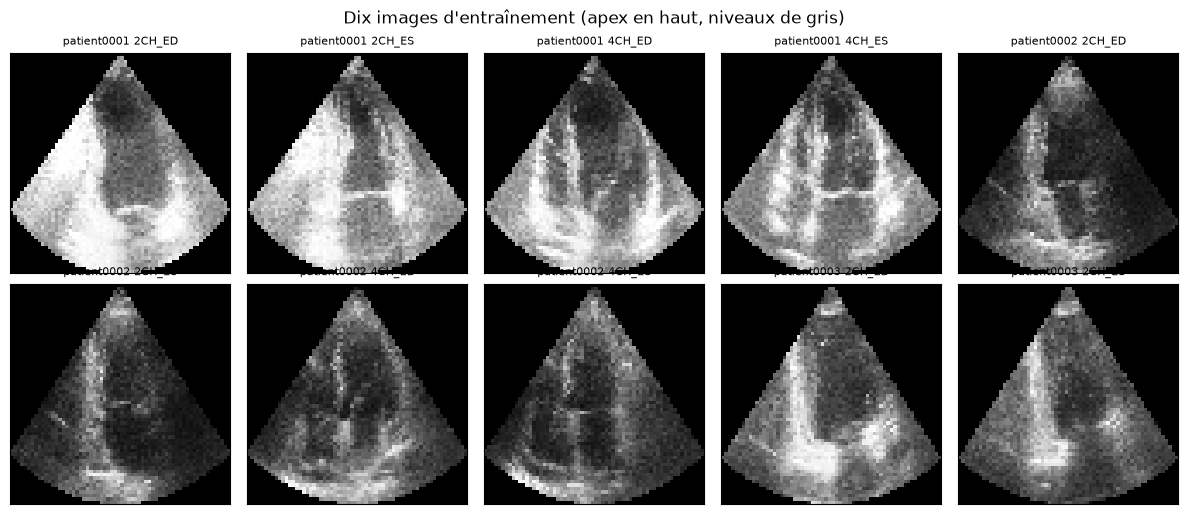

In [7]:
shapes = set()
mins, maxs = [], []
for subset in (train_dataset, valid_dataset, test_dataset):
    for record in subset.records:
        image = record["image"]
        shapes.add(tuple(image.shape))
        mins.append(float(image.min()))
        maxs.append(float(image.max()))
        stored = record["lv_area"]
        computed = float((record["label"].numpy() == 1).mean())
        assert abs(stored - computed) < 1e-6
        label_np = record["label"].numpy()
        assert abs(record["epi_area"] - float(np.isin(label_np, (1, 2)).mean())) < 1e-6
        assert abs(record["la_area"] - float((label_np == 3).mean())) < 1e-6

assert shapes == {(IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)}, shapes
assert min(mins) >= 0.0 and max(maxs) <= 1.0
print(f"Forme unique : {shapes.pop()}   canal d'entrée in_channels={IN_CHANNELS}")
print(f"Intensités sur les trois sous-ensembles : [{min(mins):.3f}, {max(maxs):.3f}]")

probe_batch = next(iter(train_loader))
area_batch = torch.as_tensor(probe_batch["lv_area"], dtype=torch.float32)
area_from_label = (probe_batch["label"] == 1).float().mean(dim=(1, 2))
assert torch.allclose(area_batch, area_from_label, atol=1e-5)
print(f"Collation de lv_area : tenseur {tuple(area_batch.shape)}, aligné sur le masque.")


def mean_lv_area(records, instant=None, view=None):
    values = [
        record["lv_area"]
        for record in records
        if (instant is None or record["instant"] == instant)
        and (view is None or record["view"] == view)
    ]
    return float(np.mean(values))


for name, subset in (
    ("entraînement", train_dataset),
    ("validation", valid_dataset),
    ("test", test_dataset),
):
    counts = Counter(record["view_instant"] for record in subset.records)
    print(
        f"{name:14s} {dict(sorted(counts.items()))}  "
        f"lv_area ED {mean_lv_area(subset.records, 'ED'):.4f}  "
        f"ES {mean_lv_area(subset.records, 'ES'):.4f}"
    )

assert mean_lv_area(train_dataset.records, "ED") > mean_lv_area(train_dataset.records, "ES")
heart_fraction = float(np.mean([
    (record["label"] > 0).float().mean().item()
    for record in train_dataset.records
]))
print(f"Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : {heart_fraction:.3f}")
print(f"Aire moyenne de la cavité VG sur l'entraînement : {mean_lv_area(train_dataset.records):.3f}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, index in zip(axes.ravel(), range(10)):
    record = train_dataset[index]
    ax.imshow(record["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{record['patient']} {record['view_instant']}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Dix images d'entraînement (apex en haut, niveaux de gris)")
fig.tight_layout()
plt.show()


## 2. Architecture (`AutoencoderKL`)

L'encodeur produit les paramètres d'une gaussienne diagonale. Trois sous-échantillonnages mènent de 64×64 à 8×8. Huit canaux latents donnent un code 8×8×8, soit 512 coefficients. Les largeurs `(32, 64, 128, 256)` sont toutes divisibles par 32, donc la GroupNorm de l'expérience 4 reste en place. Deux blocs résiduels à chaque échelle gardent de la profondeur pour les parois fines. L'attention n'est activée qu'au dernier niveau, là où les quatre cavités tiennent dans une grille 8×8.

À l'entraînement, le décodeur reçoit z = μ + ε σ. À l'évaluation, il reçoit μ. `forward` rééchantillonne même en mode `eval`, donc l'entraînement et la validation appellent `encode`, `sampling` et `decode` explicitement. `decode_image` borne la sortie à [0, 1] avant la perte et avant les métriques.

Le calcul reste en FP32. TF32 est désactivé dans la cellule de réglage CUDA : les convolutions et les produits matriciels gardent la mantisse 23 bits.


In [8]:
CHANNELS = (32, 64, 128, 256)
LATENT_CHANNELS = 8
ATTENTION_LEVELS = (False, False, False, True)
NORM_GROUPS = 32
NUM_RES_BLOCKS = 2

assert all(channel % NORM_GROUPS == 0 for channel in CHANNELS)
assert len(ATTENTION_LEVELS) == len(CHANNELS)


def build_vae(seed=SEED):
    set_seed(seed)
    model = AutoencoderKL(
        spatial_dims=2,
        in_channels=IN_CHANNELS,
        out_channels=1,
        num_res_blocks=NUM_RES_BLOCKS,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return model.to(device)


def decode_image(net, latent):
    return torch.clamp(net.decode(latent), 0.0, 1.0)


model = build_vae(SEED)
print(summary(
    model.cpu(),
    input_size=(BATCH_SIZE, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
    depth=2,
    col_names=["input_size", "output_size", "num_params"],
    verbose=0,
    device="cpu",
))
model.to(device)

with torch.no_grad():
    probe, mu, sigma = model(torch.zeros(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device))

LATENT_SHAPE = tuple(mu.shape[1:])
downsamples = len(CHANNELS) - 1
expected_latent = (
    LATENT_CHANNELS,
    IMAGE_SIZE // 2 ** downsamples,
    IMAGE_SIZE // 2 ** downsamples,
)
assert LATENT_SHAPE == expected_latent, (LATENT_SHAPE, expected_latent)
assert tuple(sigma.shape[1:]) == LATENT_SHAPE
assert tuple(probe.shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

N_PARAMS = sum(parameter.numel() for parameter in model.parameters())
pixels = IN_CHANNELS * IMAGE_SIZE * IMAGE_SIZE
latent_size = int(np.prod(LATENT_SHAPE))
print(f"Reconstruction {tuple(probe.shape)}, moyenne latente {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Paramètres entraînables : {N_PARAMS:,}".replace(",", " "))
print(f"Code latent : {latent_size} coefficients pour {pixels} pixels, compression ×{pixels / latent_size:.0f}")
print(f"VRAM allouée après un passage : {torch.cuda.memory_allocated(0) / 1024 ** 2:.1f} Mo")
print("Convolutions du goulot :")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(model, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(
        f"  {name}: noyau {tuple(conv.kernel_size)}, "
        f"pas {tuple(conv.stride)}, padding {tuple(conv.padding)}"
    )


Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
AutoencoderKL                                 [64, 1, 64, 64]           [64, 1, 64, 64]           --
├─Encoder: 1-1                                [64, 1, 64, 64]           [64, 8, 8, 8]             --
│    └─ModuleList: 2-1                        --                        --                        3,535,528
├─Convolution: 1-2                            [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-2                            [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-3                            [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-3                            [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-4                            [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-4                            [64, 8, 8, 8]             [64, 8,

Reconstruction (1, 1, 64, 64), moyenne latente (8, 8, 8), sigma (1, 8, 8, 8)
Paramètres entraînables : 8 233 153
Code latent : 512 coefficients pour 4096 pixels, compression ×8
VRAM allouée après un passage : 64.3 Mo
Convolutions du goulot :
  quant_conv_mu: noyau (1, 1), pas (1, 1), padding (0, 0)
  quant_conv_log_sigma: noyau (1, 1), pas (1, 1), padding (0, 0)
  post_quant_conv: noyau (1, 1), pas (1, 1), padding (0, 0)


## 3. Perte de netteté et entraînement

La carte de poids sert dans la MSE, la L1 et la L1 des gradients :

$$W = 1 + 3{,}5 \cdot \mathbf{1}(\mathrm{label} > 0)$$

Un pixel du cœur vaut 4,5, un pixel du fond vaut 1.

$$L_{\mathrm{mse},w} = \frac{\sum W (\hat{x} - x)^2}{\sum W}, \qquad L_{1,w} = \frac{\sum W |\hat{x} - x|}{\sum W}$$

Les gradients horizontaux et verticaux sont des différences finies. Le poids d'une différence est le maximum des deux pixels qui la portent, pour ne pas effacer le bord entre le myocarde et le fond.

$$L_{\nabla,w} = \frac{\sum W_x |\nabla_x \hat{x} - \nabla_x x| + \sum W_y |\nabla_y \hat{x} - \nabla_y x|}{\sum W_x + \sum W_y}$$

$$L_{\mathrm{recon}} = 0{,}40 \, L_{\mathrm{mse},w} + 0{,}25 \, L_{1,w} + 0{,}25 \, (1 - \mathrm{SSIM}) + 0{,}10 \, L_{\nabla,w}$$

`SSIMLoss` (fenêtre 7, `data_range` 1) vaut 1 − SSIM. La reconstruction vue par les quatre termes est déjà bornée à [0, 1]. La MSE brute, sans poids, est enregistrée à chaque époque pour la comparaison avec les expériences précédentes.

β monte linéairement de 0 à l'époque 1 jusqu'à \(\beta_{\max} = 2 \times 10^{-5}\) à l'époque 15, puis reste constant.

L'attribut est la moyenne spatiale du premier canal, \(z_0 = \mu[:, 0]\) moyenné sur les 8×8 positions. Pour chaque paire d'images du lot, avec \(a\) l'aire de la cavité (`label == 1`) :

$$L_{\mathrm{attr}} = \mathrm{moyenne}_{i \neq j} \big| \tanh(2 (z_{0,i} - z_{0,j})) - \mathrm{signe}(a_i - a_j) \big|$$

γ = 0,03 maintient le classement monotone sans reprendre la place de la texture dans les autres canaux. Le checkpoint retenu est la plus faible perte de reconstruction de validation à partir de l'époque 15, une fois β arrivé à son plateau. Le fichier de poids n'est écrit qu'une fois, à la fin de la boucle.


β max = 2e-05   γ = 0.03   δ = 2.0   époques = 100   TRAIN = True
Reconstruction = 0.40 MSE_w + 0.25 L1_w + 0.25 (1-SSIM) + 0.10 grad_w
Calendrier de β :
  époque 01  β = 0.000e+00
  époque 02  β = 1.429e-06
  époque 05  β = 5.714e-06
  époque 15  β = 2.000e-05
  époque 16  β = 2.000e-05


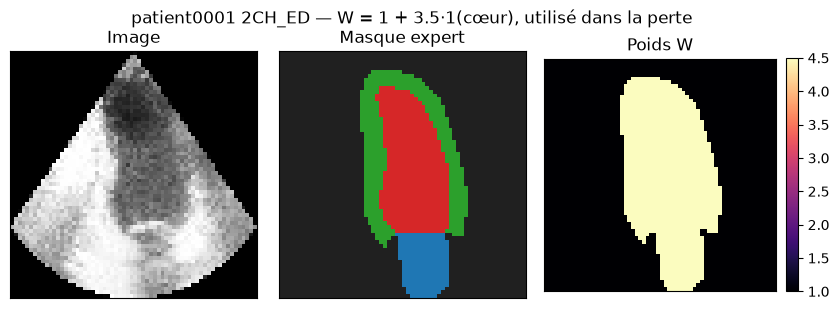

In [9]:
BETA_MAX = 2e-5
WARMUP_EPOCHS = 15
GAMMA = 0.03
DELTA = 2.0
MSE_WEIGHT = 0.40
L1_WEIGHT = 0.25
SSIM_WEIGHT = 0.25
GRAD_WEIGHT = 0.10
HEART_WEIGHT = 3.5
LR = 1e-3
WEIGHT_DECAY = 1e-5
ETA_MIN = 1e-5
N_EPOCHS = int(os.environ.get("CAMUS_EXP5_EPOCHS", "100"))
TRAIN = os.environ.get("CAMUS_EXP5_TRAIN", "1") not in {"0", "false", "False"}

ssim_loss = SSIMLoss(spatial_dims=2, data_range=1.0, win_size=7).to(device)


def beta_at(epoch):
    # Époque 1 : 0. Époque 15 et suivantes : BETA_MAX.
    progress = (epoch - 1) / (WARMUP_EPOCHS - 1)
    return BETA_MAX * min(1.0, max(0.0, progress))


def kl_divergence(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(
        mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1,
        dim=tuple(range(1, mu.ndim)),
    )
    return kl.mean()


def attribute_loss(mu, area):
    z0 = mu[:, 0].mean(dim=(1, 2))
    if z0.shape[0] < 2:
        return z0.new_zeros(())
    diff_z = z0[:, None] - z0[None, :]
    diff_a = area[:, None] - area[None, :]
    eye = torch.eye(z0.shape[0], dtype=torch.bool, device=z0.device)
    residual = torch.tanh(DELTA * diff_z) - torch.sign(diff_a)
    return residual.abs()[~eye].mean()


def weighted_gradient_l1(recon, image, weights):
    dx_recon = recon[:, :, :, 1:] - recon[:, :, :, :-1]
    dx_image = image[:, :, :, 1:] - image[:, :, :, :-1]
    dy_recon = recon[:, :, 1:, :] - recon[:, :, :-1, :]
    dy_image = image[:, :, 1:, :] - image[:, :, :-1, :]
    weight_x = torch.maximum(weights[:, :, :, 1:], weights[:, :, :, :-1])
    weight_y = torch.maximum(weights[:, :, 1:, :], weights[:, :, :-1, :])
    numerator = (weight_x * (dx_recon - dx_image).abs()).sum()
    numerator = numerator + (weight_y * (dy_recon - dy_image).abs()).sum()
    denominator = (weight_x.sum() + weight_y.sum()).clamp_min(1.0)
    return numerator / denominator


def compute_Edge_SSIM_L1_MSE_loss(recon, image, label, mu, sigma, beta):
    weights = 1.0 + HEART_WEIGHT * (label > 0).to(dtype=recon.dtype).unsqueeze(1)
    error = recon - image
    denom = weights.sum().clamp_min(1.0)
    mse_w = (weights * error.pow(2)).sum() / denom
    l1_w = (weights * error.abs()).sum() / denom
    ssim_gap = ssim_loss(recon, image)
    ssim_val = 1.0 - ssim_gap
    grad_l1_w = weighted_gradient_l1(recon, image, weights)
    recon_loss = (
        MSE_WEIGHT * mse_w
        + L1_WEIGHT * l1_w
        + SSIM_WEIGHT * (1.0 - ssim_val)
        + GRAD_WEIGHT * grad_l1_w
    )
    kl_loss = kl_divergence(mu, sigma)
    area = (label == 1).to(dtype=mu.dtype).mean(dim=(1, 2))
    attr = attribute_loss(mu, area)
    total = recon_loss + beta * kl_loss + GAMMA * attr
    mse = error.pow(2).mean()
    return (
        total,
        recon_loss.detach(),
        mse.detach(),
        kl_loss.detach(),
        attr.detach(),
        ssim_val.detach(),
        grad_l1_w.detach(),
    )


print(
    f"β max = {BETA_MAX:.0e}   γ = {GAMMA:.2f}   δ = {DELTA:.1f}   "
    f"époques = {N_EPOCHS}   TRAIN = {TRAIN}"
)
print(
    "Reconstruction = "
    f"{MSE_WEIGHT:.2f} MSE_w + {L1_WEIGHT:.2f} L1_w + "
    f"{SSIM_WEIGHT:.2f} (1-SSIM) + {GRAD_WEIGHT:.2f} grad_w"
)
print("Calendrier de β :")
for epoch in (1, 2, 5, 15, 16):
    print(f"  époque {epoch:02d}  β = {beta_at(epoch):.3e}")

example = train_dataset[0]
label_np = example["label"].numpy()
weight_np = 1.0 + HEART_WEIGHT * (label_np > 0).astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
axes[0].imshow(example["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(label_np, cmap=HEART_CMAP, vmin=0, vmax=3, interpolation="nearest")
weight_image = axes[2].imshow(weight_np, cmap="magma", vmin=1, vmax=1.0 + HEART_WEIGHT)
axes[0].set_title("Image")
axes[1].set_title("Masque expert")
axes[2].set_title("Poids W")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(weight_image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle(
    f"{example['patient']} {example['view_instant']} — "
    f"W = 1 + {HEART_WEIGHT:.1f}·1(cœur), utilisé dans la perte"
)
fig.tight_layout()
plt.show()


In [10]:
CONFIG = {
    "spatial_dims": 2,
    "in_channels": IN_CHANNELS,
    "out_channels": 1,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "latent_channels": LATENT_CHANNELS,
    "latent_shape": list(LATENT_SHAPE),
    "norm_num_groups": NORM_GROUPS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_mse_weight": MSE_WEIGHT,
    "recon_l1_weight": L1_WEIGHT,
    "recon_ssim_weight": SSIM_WEIGHT,
    "recon_grad_weight": GRAD_WEIGHT,
    "heart_weight": HEART_WEIGHT,
    "recon_loss": "0.40*weighted_mse+0.25*weighted_l1+0.25*(1-ssim)+0.10*weighted_grad_l1",
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "precision": "fp32",
    "epochs": N_EPOCHS,
    "device": gpu_name,
}

LOSS_KEYS = ("total", "recon", "mse", "ssim", "kl", "attr", "grad")


def preload_split(dataset):
    images = torch.stack([record["image"] for record in dataset.records]).contiguous()
    labels = torch.stack([record["label"] for record in dataset.records]).contiguous()
    return images.to(device), labels.to(device)


def iter_gpu_batches(images, labels, batch_size, shuffle):
    count = images.shape[0]
    if shuffle:
        order = torch.randperm(count, device=images.device)
    else:
        order = torch.arange(count, device=images.device)
    for start in range(0, count, batch_size):
        index = order[start:start + batch_size]
        yield images.index_select(0, index), labels.index_select(0, index)


def empty_sums():
    return {key: torch.zeros((), device=device) for key in LOSS_KEYS}


def accumulate_split(images, labels, beta, train):
    sums = empty_sums()
    nonfinite = torch.zeros((), dtype=torch.float32, device=device)
    seen = 0
    for batch_images, batch_labels in iter_gpu_batches(images, labels, BATCH_SIZE, shuffle=train):
        if train:
            optimizer.zero_grad(set_to_none=True)
        mu, sigma = model.encode(batch_images)
        latent = model.sampling(mu, sigma) if train else mu
        recon = decode_image(model, latent)
        total, recon_loss, mse, kl_loss, attr, ssim_val, grad_l1 = compute_Edge_SSIM_L1_MSE_loss(
            recon, batch_images, batch_labels, mu, sigma, beta,
        )
        if train:
            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        scale = total.new_tensor(float(batch_images.shape[0]))
        sums["total"] = sums["total"] + total.detach() * scale
        sums["recon"] = sums["recon"] + recon_loss * scale
        sums["mse"] = sums["mse"] + mse * scale
        sums["ssim"] = sums["ssim"] + ssim_val * scale
        sums["kl"] = sums["kl"] + kl_loss * scale
        sums["attr"] = sums["attr"] + attr * scale
        sums["grad"] = sums["grad"] + grad_l1 * scale
        nonfinite = nonfinite + (~torch.isfinite(total.detach())).to(dtype=torch.float32)
        seen += int(batch_images.shape[0])
    payload = torch.stack([sums[key] / seen for key in LOSS_KEYS] + [nonfinite])
    values = payload.detach().cpu().tolist()
    return dict(zip(LOSS_KEYS, values[:-1])), values[-1] != 0.0


def train_vae(model, n_epochs, config, lr=LR):
    global optimizer
    set_seed(SEED)
    train_images, train_labels = preload_split(train_dataset)
    valid_images, valid_labels = preload_split(valid_dataset)
    print(
        f"Préchargement VRAM : train {tuple(train_images.shape)}, "
        f"val {tuple(valid_images.shape)}, "
        f"{torch.cuda.memory_allocated() / 1024 ** 2:.0f} Mo alloués"
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(n_epochs, 1), eta_min=ETA_MIN,
    )
    history = {
        key: []
        for key in (
            "train_total", "train_recon", "train_mse", "train_ssim", "train_kl", "train_attr", "train_grad",
            "val_total", "val_recon", "val_mse", "val_ssim", "val_kl", "val_attr", "val_grad",
            "beta", "lr",
        )
    }
    history.update({
        "beta_max": BETA_MAX,
        "gamma": GAMMA,
        "delta": DELTA,
        "epochs": n_epochs,
        "warmup_epochs": WARMUP_EPOCHS,
        "recon": CONFIG["recon_loss"],
        "selection": "val_recon",
    })
    best_score = float("inf")
    best_state = None
    best_epoch = 0
    torch.cuda.reset_peak_memory_stats()
    clock = time.perf_counter()
    log_path = ARTIFACT_DIR / "exp5_train.log"
    log_file = log_path.open("w", encoding="utf-8")
    print(
        f"Sélection sur la reconstruction de validation à partir de l'époque {WARMUP_EPOCHS}. "
        f"Journal : {log_path}. Le fichier .pth est écrit une seule fois à la fin."
    )

    for epoch in range(n_epochs):
        beta = beta_at(epoch + 1)
        lr_now = float(optimizer.param_groups[0]["lr"])
        model.train()
        train_means, train_bad = accumulate_split(train_images, train_labels, beta, train=True)
        if train_bad:
            raise RuntimeError(f"Perte d'entraînement non finie à l'époque {epoch + 1}")
        model.eval()
        with torch.no_grad():
            val_means, val_bad = accumulate_split(valid_images, valid_labels, beta, train=False)
        if val_bad:
            raise RuntimeError(f"Perte de validation non finie à l'époque {epoch + 1}")

        for key in LOSS_KEYS:
            history[f"train_{key}"].append(train_means[key])
            history[f"val_{key}"].append(val_means[key])
        history["beta"].append(beta)
        history["lr"].append(lr_now)

        saved = False
        if (epoch + 1) >= WARMUP_EPOCHS and val_means["recon"] < best_score:
            best_score = val_means["recon"]
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            history["best_epoch"] = best_epoch
            history["best_val"] = best_score
            saved = True

        flag = "  meilleur val_recon" if saved else ""
        line = (
            f"Époque {epoch + 1:02d}/{n_epochs}  "
            f"β={beta:.2e}  lr={lr_now:.2e}  "
            f"train {train_means['total']:.5f} "
            f"(recon {train_means['recon']:.5f}, mse {train_means['mse']:.5f}, "
            f"ssim {train_means['ssim']:.3f}, grad {train_means['grad']:.5f}, "
            f"kl {train_means['kl']:.2f}, attr {train_means['attr']:.4f})  "
            f"val {val_means['total']:.5f} "
            f"(recon {val_means['recon']:.5f}, mse {val_means['mse']:.5f}, "
            f"ssim {val_means['ssim']:.3f}, grad {val_means['grad']:.5f}, "
            f"kl {val_means['kl']:.2f}, attr {val_means['attr']:.4f})"
            f"{flag}"
        )
        print(line, flush=True)
        log_file.write(line + "\n")
        log_file.flush()
        scheduler.step()

    history["seconds"] = time.perf_counter() - clock
    history["best_epoch"] = best_epoch
    history["best_val"] = best_score
    history["max_memory_mb"] = torch.cuda.max_memory_allocated() / (1024 ** 2)
    if best_state is None:
        raise RuntimeError("Aucun checkpoint : la sélection n'a retenu aucune époque.")
    model.load_state_dict(best_state)
    torch.save(
        {
            "state_dict": best_state,
            "epoch": best_epoch,
            "history": history,
            "config": config,
        },
        CHECKPOINT_PATH,
    )
    log_file.write(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"reconstruction de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo.\n"
    )
    log_file.close()
    print(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"reconstruction de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo."
    )
    print(f"Poids enregistrés dans {CHECKPOINT_PATH}.")
    return model, history


model = build_vae(SEED)
if TRAIN:
    model, history = train_vae(model, N_EPOCHS, CONFIG, lr=LR)
else:
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
    payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(payload["state_dict"])
    history = payload["history"]
    print(f"Poids rechargés : {CHECKPOINT_PATH} (époque {history['best_epoch']})")


Préchargement VRAM : train (1600, 1, 64, 64), val (200, 1, 64, 64), 182 Mo alloués
Sélection sur la reconstruction de validation à partir de l'époque 15. Journal : artifacts\exp5_train.log. Le fichier .pth est écrit une seule fois à la fin.


Époque 01/100  β=0.00e+00  lr=1.00e-03  train 0.26365 (recon 0.24226, mse 0.04930, ssim 0.324, grad 0.06970, kl 2490845.75, attr 0.7129)  val 0.19169 (recon 0.17378, mse 0.02019, ssim 0.459, grad 0.05687, kl 3753.13, attr 0.5970)


Époque 02/100  β=1.43e-06  lr=1.00e-03  train 0.18025 (recon 0.16222, mse 0.01829, ssim 0.506, grad 0.05870, kl 2493.11, attr 0.4824)  val 0.15603 (recon 0.14114, mse 0.01292, ssim 0.563, grad 0.05600, kl 1593.71, attr 0.4206)


Époque 03/100  β=2.86e-06  lr=9.99e-04  train 0.15394 (recon 0.13836, mse 0.01357, ssim 0.579, grad 0.05766, kl 1400.40, attr 0.3860)  val 0.14127 (recon 0.12566, mse 0.01097, ssim 0.615, grad 0.05540, kl 1478.11, attr 0.3797)


Époque 04/100  β=4.29e-06  lr=9.98e-04  train 0.14179 (recon 0.12687, mse 0.01204, ssim 0.617, grad 0.05701, kl 1037.76, attr 0.3489)  val 0.13405 (recon 0.11825, mse 0.00982, ssim 0.640, grad 0.05527, kl 1217.22, attr 0.3528)


Époque 05/100  β=5.71e-06  lr=9.96e-04  train 0.13549 (recon 0.12105, mse 0.01139, ssim 0.637, grad 0.05653, kl 878.65, attr 0.3139)  val 0.12490 (recon 0.10969, mse 0.00935, ssim 0.670, grad 0.05452, kl 833.00, attr 0.3483)


... (92 outputs left out)

Époque 98/100  β=2.00e-05  lr=1.22e-05  train 0.05721 (recon 0.04444, mse 0.00175, ssim 0.873, grad 0.04164, kl 472.64, attr 0.1106)  val 0.08673 (recon 0.06806, mse 0.00262, ssim 0.791, grad 0.04840, kl 443.30, attr 0.3268)


Époque 99/100  β=2.00e-05  lr=1.10e-05  train 0.05719 (recon 0.04439, mse 0.00174, ssim 0.873, grad 0.04163, kl 470.67, attr 0.1131)  val 0.08673 (recon 0.06807, mse 0.00262, ssim 0.791, grad 0.04839, kl 443.35, attr 0.3264)


Époque 100/100  β=2.00e-05  lr=1.02e-05  train 0.05713 (recon 0.04435, mse 0.00174, ssim 0.873, grad 0.04162, kl 471.39, attr 0.1117)  val 0.08674 (recon 0.06810, mse 0.00263, ssim 0.791, grad 0.04842, kl 443.25, attr 0.3259)


Meilleure époque 48/100, reconstruction de validation 0.061307, durée 6.30 min, VRAM crête 2997 Mo.
Poids enregistrés dans checkpoints\exp5_vae_best.pth.


### Courbes

La courbe de SSIM est le SSIM de MONAI, avec la même fenêtre que le terme optimisé. La MSE tracée est la MSE brute, celle des tableaux de test. La courbe de gradient est la L1 pondérée des différences finies.

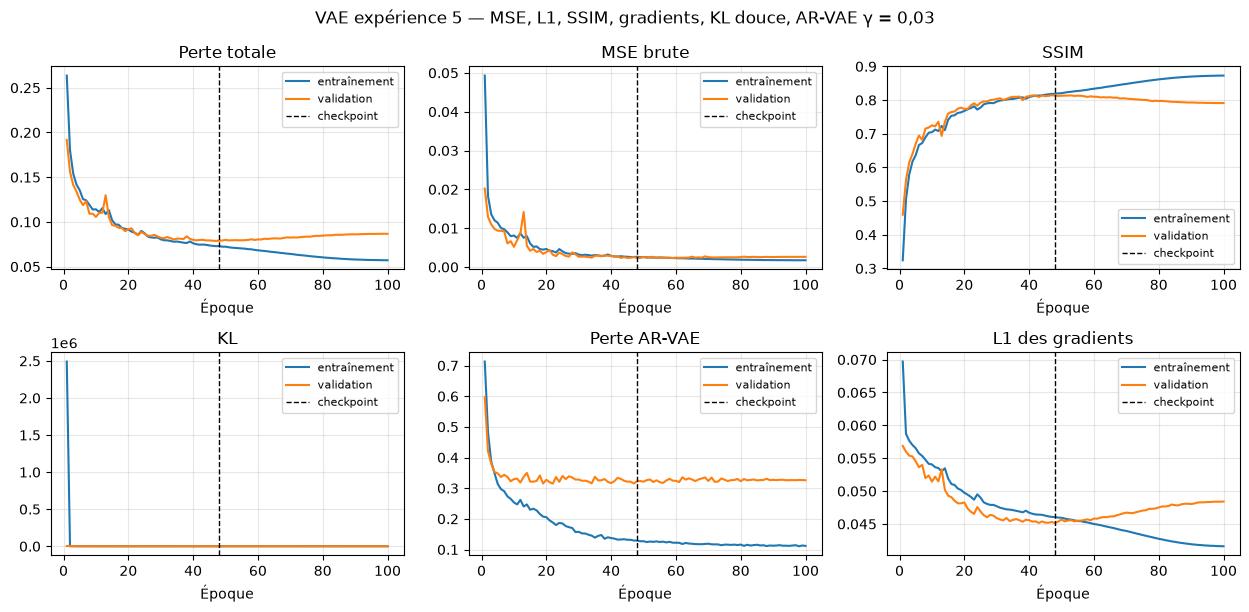

In [11]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.2))
    series = (
        ("total", "Perte totale"),
        ("mse", "MSE brute"),
        ("ssim", "SSIM"),
        ("kl", "KL"),
        ("attr", "Perte AR-VAE"),
        ("grad", "L1 des gradients"),
    )
    for ax, (key, title) in zip(axes.ravel(), series):
        ax.plot(epochs, history[f"train_{key}"], label="entraînement")
        ax.plot(epochs, history[f"val_{key}"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
        ax.set_title(title)
        ax.set_xlabel("Époque")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle("VAE expérience 5 — MSE, L1, SSIM, gradients, KL douce, AR-VAE γ = 0,03")
    fig.tight_layout()
    plt.show()


plot_history(history)


## 4. Évaluation

Les métriques de test décodent μ. La MSE, la MAE, le PSNR et le SSIM utilisent les mêmes définitions que les expériences 1 à 3 : PSNR avec `max_val` 1, SSIM de MONAI avec une fenêtre de 7. La MSE cœur moyenne l'erreur quadratique sur les pixels `label > 0`. La MSE fond fait de même sur `label == 0`. Le PSNR cœur est `10 log10(1 / MSE cœur)` sur chaque image, puis moyenné.


Poids rechargés : époque 48, reconstruction de validation 0.061307, durée 6.30 min.


MSE moyenne sur les 200 images de test : 0.00268 ± 0.00138
MAE test :  0.028 ± 0.006
PSNR test : 26.04 ± 1.50 dB
SSIM test : 0.808 ± 0.022
MSE sur le cœur : 0.00446 ± 0.00159
MSE sur le fond : 0.00212 ± 0.00149
PSNR sur le cœur : 23.73 ± 1.33 dB


### MSE, PSNR et SSIM de test par vue et par instant

| Vue / instant | n | MSE | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| 2CH_ED | 50 | 0.00270 | 26.01 | 0.803 |
| 2CH_ES | 50 | 0.00255 | 26.34 | 0.800 |
| 4CH_ED | 50 | 0.00284 | 25.70 | 0.815 |
| 4CH_ES | 50 | 0.00262 | 26.10 | 0.814 |

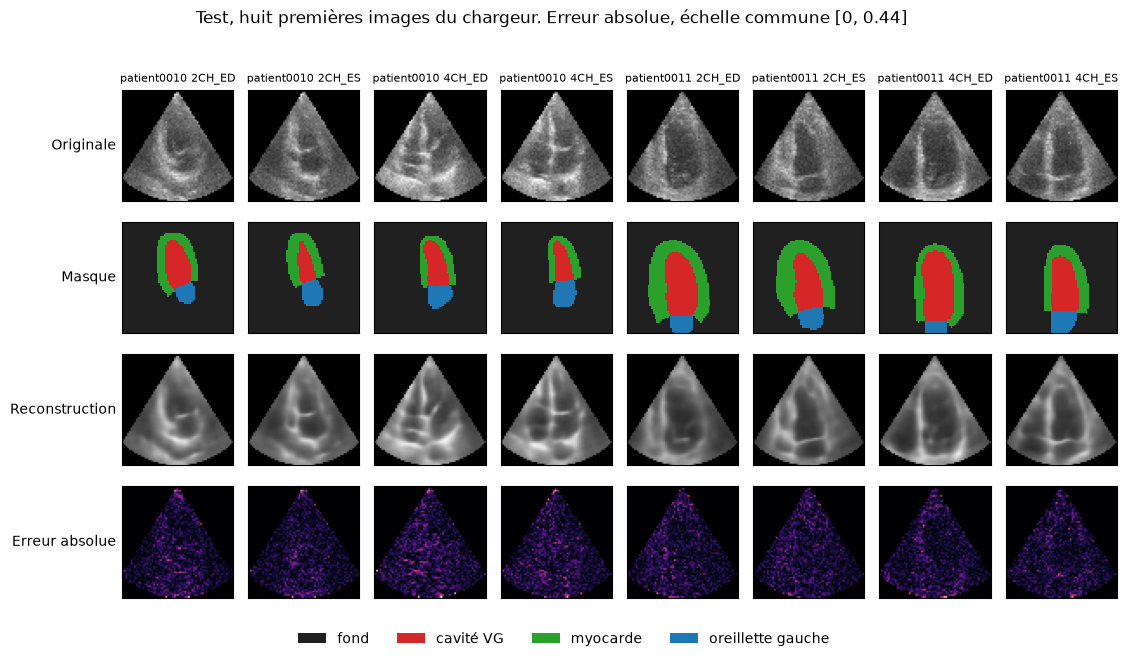

In [12]:
def make_ssim():
    return SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def reconstruction_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim


def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.mean(values)), float(np.std(values))


def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"


def fmt_pm(mean, std, digits):
    if mean is None:
        return "n.d."
    if std is None:
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def fmt_int(value):
    if value is None:
        return "n.d."
    return f"{int(value):,}".replace(",", " ")


def masked_mse(recon, image, label, inside):
    error = (recon - image).pow(2)
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()


def as_float_vector(value):
    if torch.is_tensor(value):
        return value.detach().cpu().float().reshape(-1)
    return torch.tensor(value, dtype=torch.float32).reshape(-1)


@torch.no_grad()
def collect_predictions(net, loader):
    net.eval()
    images, recons, labels, mus, areas = [], [], [], [], []
    epi_areas, la_areas = [], []
    view_instants, views, instants, patients = [], [], [], []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        mu, sigma = net.encode(x)
        recon = decode_image(net, mu)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        mus.append(mu.cpu())
        areas.append(as_float_vector(batch["lv_area"]))
        epi_areas.append(as_float_vector(batch["epi_area"]))
        la_areas.append(as_float_vector(batch["la_area"]))
        view_instants.extend(list(batch["view_instant"]))
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "mu": torch.cat(mus),
        "lv_area": torch.cat(areas).numpy(),
        "epi_area": torch.cat(epi_areas).numpy(),
        "la_area": torch.cat(la_areas).numpy(),
        "view_instant": np.asarray(view_instants),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
    }
    mae, mse, psnr, ssim = reconstruction_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)


if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
saved_config = payload["config"]
assert tuple(saved_config["channels"]) == tuple(CHANNELS)
assert saved_config["latent_channels"] == LATENT_CHANNELS
assert saved_config["num_res_blocks"] == NUM_RES_BLOCKS
model.load_state_dict(payload["state_dict"])
history = payload["history"]
model.eval()
print(
    f"Poids rechargés : époque {payload['epoch']}, "
    f"reconstruction de validation {history['best_val']:.6f}, "
    f"durée {history['seconds'] / 60:.2f} min."
)

test_pred = collect_predictions(model, test_loader)
assert len(test_pred["mse"]) == len(test_dataset) == 200
heart_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=True)
background_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=False)

print(f"MSE moyenne sur les {len(test_dataset)} images de test : {fmt_mean_std(test_pred['mse'], digits=5)}")
print(f"MAE test :  {fmt_mean_std(test_pred['mae'])}")
print(f"PSNR test : {fmt_mean_std(test_pred['psnr'], digits=2)} dB")
print(f"SSIM test : {fmt_mean_std(test_pred['ssim'])}")
print(f"MSE sur le cœur : {fmt_mean_std(heart_mse, digits=5)}")
heart_psnr = -10.0 * np.log10(np.clip(heart_mse, 1e-12, None))
print(f"MSE sur le fond : {fmt_mean_std(background_mse, digits=5)}")
print(f"PSNR sur le cœur : {fmt_mean_std(heart_psnr, digits=2)} dB")

per_class_rows = []
per_view_instant = {}
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    mse_mean, mse_std = mean_std(test_pred["mse"][selected])
    psnr_mean, psnr_std = mean_std(test_pred["psnr"][selected])
    ssim_mean, ssim_std = mean_std(test_pred["ssim"][selected])
    per_class_rows.append([
        view_instant,
        int(selected.sum()),
        f"{mse_mean:.5f}",
        f"{psnr_mean:.2f}",
        f"{ssim_mean:.3f}",
    ])
    per_view_instant[view_instant] = {
        "n": int(selected.sum()),
        "mse_mean": mse_mean,
        "mse_std": mse_std,
        "psnr_mean": psnr_mean,
        "psnr_std": psnr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
    }

display(Markdown(
    "### MSE, PSNR et SSIM de test par vue et par instant\n\n"
    + markdown_table(["Vue / instant", "n", "MSE", "PSNR (dB)", "SSIM"], per_class_rows)
))

n_show = 8
shown_error = (test_pred["recon"][:n_show] - test_pred["image"][:n_show]).abs()
error_vmax = float(shown_error.max().clamp_min(1e-3))
fig, axes = plt.subplots(4, n_show, figsize=(1.45 * n_show, 6.6))
row_names = ("Originale", "Masque", "Reconstruction", "Erreur absolue")
for index in range(n_show):
    axes[0, index].imshow(test_pred["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].imshow(
        test_pred["label"][index].numpy(),
        cmap=HEART_CMAP,
        vmin=0,
        vmax=3,
        interpolation="nearest",
    )
    axes[2, index].imshow(test_pred["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[3, index].imshow(shown_error[index, 0].numpy(), cmap="magma", vmin=0, vmax=error_vmax)
    axes[0, index].set_title(
        f"{test_pred['patient'][index]} {test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for row in range(4):
        axes[row, index].set_xticks([])
        axes[row, index].set_yticks([])
for row, name in enumerate(row_names):
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
legend = [
    Patch(facecolor=HEART_CMAP(index / 3), edgecolor="none", label=LABEL_NAMES[index])
    for index in range(4)
]
fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False)
fig.suptitle(
    f"Test, huit premières images du chargeur. Erreur absolue, échelle commune [0, {error_vmax:.2f}]"
)
fig.tight_layout(rect=(0.02, 0.05, 1, 0.96))
plt.show()


### Analyse de Fidélité & Cartes d'Erreur

Quatre cadres de test, un par couple vue / instant. De gauche à droite : l'image originale, la reconstruction avec les contours expert (cavité en rouge, myocarde en vert, oreillette en bleu), l'erreur absolue amplifiée cinq fois, et le profil d'intensité sur la ligne du centroïde de la cavité ventriculaire gauche. La ligne cyan marque cette coupe.


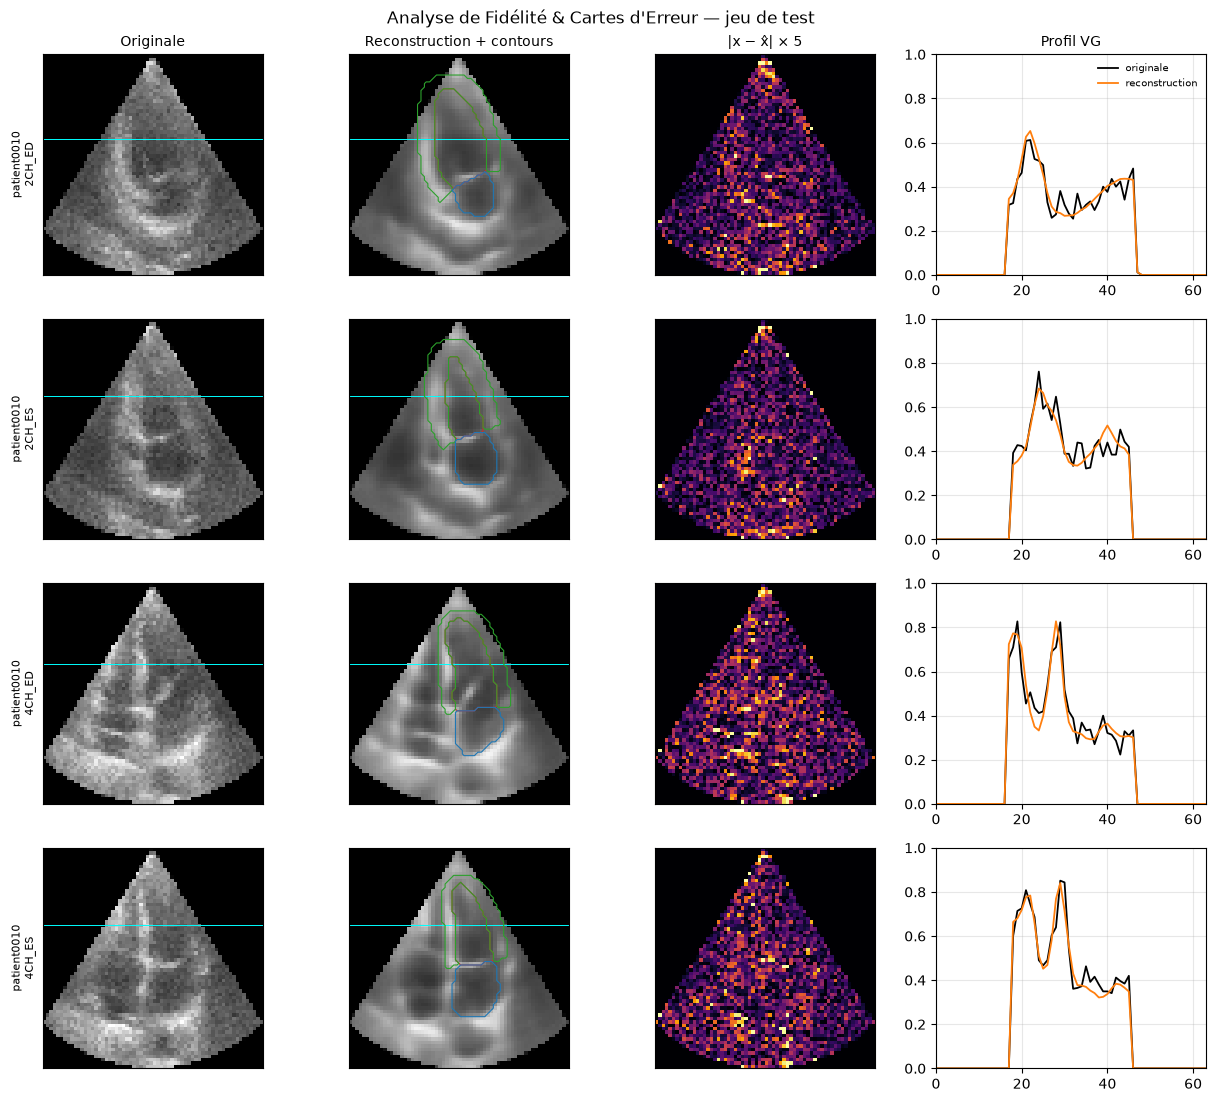

In [13]:
def lv_cut_row(label):
    cavity = label == 1
    if not cavity.any():
        return int(label.shape[0] // 2)
    rows = np.flatnonzero(cavity.any(axis=1))
    return int(round(rows.mean()))


contour_colors = {1: "#d62728", 2: "#2ca02c", 3: "#1f77b4"}
fidelity_index = []
for view_instant in VIEWS:
    matches = np.flatnonzero(test_pred["view_instant"] == view_instant)
    if len(matches) == 0:
        raise RuntimeError(f"Aucun cadre de test pour {view_instant}.")
    fidelity_index.append(int(matches[0]))

fig, axes = plt.subplots(len(fidelity_index), 4, figsize=(12.4, 11.2))
column_names = ("Originale", "Reconstruction + contours", "|x − x̂| × 5", "Profil VG")
for row, index in enumerate(fidelity_index):
    image = test_pred["image"][index, 0].numpy()
    recon = test_pred["recon"][index, 0].clamp(0, 1).numpy()
    label = test_pred["label"][index].numpy()
    cut = lv_cut_row(label)
    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].axhline(cut, color="cyan", lw=0.7)
    axes[row, 1].imshow(recon, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].axhline(cut, color="cyan", lw=0.7)
    for class_id, color in contour_colors.items():
        if np.any(label == class_id):
            axes[row, 1].contour(
                (label == class_id).astype(np.float32),
                levels=[0.5],
                colors=[color],
                linewidths=0.8,
            )
    axes[row, 2].imshow(np.abs(image - recon) * 5.0, cmap="inferno", vmin=0, vmax=1)
    axes[row, 3].plot(image[cut], color="black", lw=1.3, label="originale")
    axes[row, 3].plot(recon[cut], color="tab:orange", lw=1.3, label="reconstruction")
    axes[row, 3].set_xlim(0, image.shape[1] - 1)
    axes[row, 3].set_ylim(0, 1)
    axes[row, 3].grid(True, alpha=0.3)
    axes[row, 0].set_ylabel(
        f"{test_pred['patient'][index]}\n{test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for column in range(3):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
for column, name in enumerate(column_names):
    axes[0, column].set_title(name, fontsize=10)
axes[0, 3].legend(frameon=False, fontsize=7)
fig.suptitle("Analyse de Fidélité & Cartes d'Erreur — jeu de test")
fig.tight_layout()
plt.show()


### Comparaison des cinq expériences

Les fichiers `artifacts/results_exp2.json`, `artifacts/results_exp3.json` et `artifacts/results_exp4.json` sont relus lorsqu'ils sont présents. Sinon, le tableau reprend les chiffres imprimés par les notebooks déjà exécutés. L'expérience 4 vient de `artifacts/results_exp4.json`. L'expérience 5 est le passage en cours. Une valeur en gras est la meilleure de la ligne : plus basse pour les erreurs et les durées, plus haute pour le PSNR, le SSIM et le Spearman.

In [14]:
PUBLISHED = {
    "1": {
        "name": "Expérience 1",
        "hardware": "CPU",
        "latent": "4×8×8",
        "n_params": 473_649,
        "epochs": 25,
        "best_epoch": 25,
        "seconds": 26.8 * 60,
        "mse": 0.01024,
        "mse_std": 0.01093,
        "mae": 0.057,
        "mae_std": 0.026,
        "psnr": 20.97,
        "psnr_std": 2.68,
        "ssim": 0.622,
        "ssim_std": 0.070,
        "heart_mse": 0.01511,
        "heart_mse_std": 0.01215,
        "background_mse": 0.00871,
        "background_mse_std": 0.01079,
        "spearman": None,
        "source": "tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques)",
    },
    "2": {
        "name": "Expérience 2",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 1_888_449,
        "epochs": 20,
        "best_epoch": 19,
        "seconds": 30.5 * 60,
        "mse": 0.00765,
        "mse_std": 0.00538,
        "mae": 0.055,
        "mae_std": 0.016,
        "psnr": 21.70,
        "psnr_std": 1.92,
        "ssim": 0.445,
        "ssim_std": 0.065,
        "heart_mse": 0.01073,
        "heart_mse_std": 0.00486,
        "background_mse": 0.00678,
        "background_mse_std": 0.00624,
        "spearman": None,
        "source": "sorties exécutées de exp_2_vae_camus.ipynb",
    },
    "3": {
        "name": "Expérience 3",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 478_417,
        "epochs": 20,
        "best_epoch": 20,
        "seconds": 12.6 * 60,
        "mse": 0.01024,
        "mse_std": 0.01042,
        "mae": 0.061,
        "mae_std": 0.026,
        "psnr": 20.84,
        "psnr_std": 2.48,
        "ssim": 0.703,
        "ssim_std": 0.052,
        "heart_mse": 0.01298,
        "heart_mse_std": 0.01028,
        "background_mse": 0.00938,
        "background_mse_std": 0.01090,
        "spearman": 0.023,
        "source": "sorties exécutées de exp_3_vae_camus.ipynb",
    },
}


def load_json(path):
    if not path.is_file():
        print(f"{path} est absent. Chiffres publiés dans le notebook correspondant.")
        return None
    print(f"Lecture de {path}.")
    return json.loads(path.read_text(encoding="utf-8"))


def column_from_report(name, report, hardware, source):
    test = report["test"]
    latent = report.get("latent_shape")
    spearman = None
    latent_block = report.get("latent_attribute") or {}
    if "spearman_mu0_lv_area" in latent_block:
        spearman = float(latent_block["spearman_mu0_lv_area"])
    column = {
        "name": name,
        "hardware": hardware,
        "latent": "×".join(str(value) for value in latent) if latent else None,
        "n_params": report.get("n_params"),
        "epochs": report.get("epochs"),
        "best_epoch": report.get("best_epoch"),
        "seconds": report.get("seconds"),
        "mse": test.get("mse_mean"),
        "mse_std": test.get("mse_std"),
        "mae": test.get("mae_mean"),
        "mae_std": test.get("mae_std"),
        "psnr": test.get("psnr_mean"),
        "psnr_std": test.get("psnr_std"),
        "ssim": test.get("ssim_mean"),
        "ssim_std": test.get("ssim_std"),
        "heart_mse": test.get("heart_mse_mean"),
        "heart_mse_std": test.get("heart_mse_std"),
        "background_mse": test.get("background_mse_mean"),
        "background_mse_std": test.get("background_mse_std"),
        "heart_psnr": test.get("heart_psnr_mean"),
        "heart_psnr_std": test.get("heart_psnr_std"),
        "spearman": spearman,
        "source": source,
    }
    return column


exp2_report = load_json(ARTIFACT_DIR / "results_exp2.json")
exp3_report = load_json(ARTIFACT_DIR / "results_exp3.json")
column_exp1 = dict(PUBLISHED["1"])
column_exp2 = (
    column_from_report("Expérience 2", exp2_report, "CPU", "artifacts/results_exp2.json")
    if exp2_report is not None else dict(PUBLISHED["2"])
)
column_exp3 = (
    column_from_report("Expérience 3", exp3_report, "CPU", "artifacts/results_exp3.json")
    if exp3_report is not None else dict(PUBLISHED["3"])
)
if column_exp3.get("spearman") is None:
    column_exp3["spearman"] = PUBLISHED["3"]["spearman"]

exp4_report = load_json(ARTIFACT_DIR / "results_exp4.json")
if exp4_report is None:
    raise FileNotFoundError("artifacts/results_exp4.json est requis pour comparer l'expérience 5.")
column_exp4 = column_from_report(
    "Expérience 4",
    exp4_report,
    exp4_report.get("gpu", "GPU"),
    "artifacts/results_exp4.json",
)

exp5_mse, exp5_mse_std = mean_std(test_pred["mse"])
exp5_mae, exp5_mae_std = mean_std(test_pred["mae"])
exp5_psnr, exp5_psnr_std = mean_std(test_pred["psnr"])
exp5_ssim, exp5_ssim_std = mean_std(test_pred["ssim"])
exp5_heart, exp5_heart_std = mean_std(heart_mse)
exp5_heart_psnr, exp5_heart_psnr_std = mean_std(heart_psnr)
exp5_background, exp5_background_std = mean_std(background_mse)

column_exp5 = {
    "name": "Expérience 5",
    "hardware": gpu_name,
    "latent": "×".join(str(value) for value in LATENT_SHAPE),
    "n_params": N_PARAMS,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "seconds": history["seconds"],
    "mse": exp5_mse,
    "mse_std": exp5_mse_std,
    "mae": exp5_mae,
    "mae_std": exp5_mae_std,
    "psnr": exp5_psnr,
    "psnr_std": exp5_psnr_std,
    "ssim": exp5_ssim,
    "ssim_std": exp5_ssim_std,
    "heart_mse": exp5_heart,
    "heart_mse_std": exp5_heart_std,
    "heart_psnr": exp5_heart_psnr,
    "heart_psnr_std": exp5_heart_psnr_std,
    "background_mse": exp5_background,
    "background_mse_std": exp5_background_std,
    "spearman": None,
    "source": "test_loader, checkpoints/exp5_vae_best.pth",
}
comparison_columns = {
    "1": column_exp1,
    "2": column_exp2,
    "3": column_exp3,
    "4": column_exp4,
    "5": column_exp5,
}


def minutes_display(column):
    if column["seconds"] is None:
        return "n.d."
    minutes = column["seconds"] / 60
    return f"{minutes:.1f} min" if minutes >= 1 else f"{minutes * 60:.1f} s"


def per_epoch_display(column):
    if column["seconds"] is None or not column["epochs"]:
        return "n.d."
    value = column["seconds"] / column["epochs"]
    column["seconds_per_epoch"] = value
    return f"{value:.1f} s" if value >= 10 else f"{value:.2f} s"


def epochs_display(column):
    if column["epochs"] is None:
        return "n.d."
    if column["best_epoch"] is None:
        return str(column["epochs"])
    return f"{column['epochs']} (meilleure {column['best_epoch']})"


def mark_best(displays, values, higher):
    valid = [value for value in values if value is not None]
    if not valid:
        return displays
    target = max(valid) if higher else min(valid)
    marked = []
    for display, value in zip(displays, values):
        if value is not None and abs(value - target) <= 1e-9 * max(1.0, abs(target)):
            marked.append(f"**{display}**")
        else:
            marked.append(display)
    return marked


ordered = [column_exp1, column_exp2, column_exp3, column_exp4, column_exp5]
headers = ["", *[column["name"] for column in ordered]]


def row(label, displays, values, higher):
    return [label, *mark_best(displays, values, higher)]


table_rows = [
    ["Matériel", *[column["hardware"] for column in ordered]],
    ["Code latent", *[column["latent"] or "n.d." for column in ordered]],
    ["Paramètres", *[fmt_int(column["n_params"]) for column in ordered]],
    ["Époques", *[epochs_display(column) for column in ordered]],
    row(
        "Durée totale",
        [minutes_display(column) for column in ordered],
        [column["seconds"] for column in ordered],
        higher=False,
    ),
    row(
        "Durée par époque",
        [per_epoch_display(column) for column in ordered],
        [column.get("seconds_per_epoch") for column in ordered],
        higher=False,
    ),
    row(
        "MSE test",
        [fmt_pm(column["mse"], column["mse_std"], 5) for column in ordered],
        [column["mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MAE test",
        [fmt_pm(column["mae"], column["mae_std"], 3) for column in ordered],
        [column["mae"] for column in ordered],
        higher=False,
    ),
    row(
        "PSNR test (dB)",
        [fmt_pm(column["psnr"], column["psnr_std"], 2) for column in ordered],
        [column["psnr"] for column in ordered],
        higher=True,
    ),
    row(
        "PSNR cœur (dB)",
        [fmt_pm(column.get("heart_psnr"), column.get("heart_psnr_std"), 2) for column in ordered],
        [column.get("heart_psnr") for column in ordered],
        higher=True,
    ),
    row(
        "SSIM test",
        [fmt_pm(column["ssim"], column["ssim_std"], 3) for column in ordered],
        [column["ssim"] for column in ordered],
        higher=True,
    ),
    row(
        "MSE cœur",
        [fmt_pm(column["heart_mse"], column["heart_mse_std"], 5) for column in ordered],
        [column["heart_mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MSE fond",
        [fmt_pm(column["background_mse"], column["background_mse_std"], 5) for column in ordered],
        [column["background_mse"] for column in ordered],
        higher=False,
    ),
]

display(Markdown(
    "### Test, expériences 1, 2, 3, 4 et 5\n\n"
    + markdown_table(headers, table_rows)
    + "\n\nSources : "
    + " ; ".join(f"{column['name']} — {column['source']}" for column in ordered)
    + ". Le Spearman est ajouté après la lecture de l'espace latent."
))


artifacts\results_exp2.json est absent. Chiffres publiés dans le notebook correspondant.
artifacts\results_exp3.json est absent. Chiffres publiés dans le notebook correspondant.
Lecture de artifacts\results_exp4.json.


### Test, expériences 1, 2, 3, 4 et 5

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 | Expérience 5 |
| --- | --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 8×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 | 8 233 153 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) | 100 (meilleure 48) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** | 6.3 min |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** | 3.78 s |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | 0.00343 ± 0.00261 | **0.00268 ± 0.00138** |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | 0.034 ± 0.010 | **0.028 ± 0.006** |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | 25.12 ± 1.70 | **26.04 ± 1.50** |
| PSNR cœur (dB) | n.d. | n.d. | n.d. | n.d. | **23.73 ± 1.33** |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | 0.787 ± 0.030 | **0.808 ± 0.022** |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | 0.00518 ± 0.00206 | **0.00446 ± 0.00159** |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | 0.00292 ± 0.00315 | **0.00212 ± 0.00149** |

Sources : Expérience 1 — tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques) ; Expérience 2 — sorties exécutées de exp_2_vae_camus.ipynb ; Expérience 3 — sorties exécutées de exp_3_vae_camus.ipynb ; Expérience 4 — artifacts/results_exp4.json ; Expérience 5 — test_loader, checkpoints/exp5_vae_best.pth. Le Spearman est ajouté après la lecture de l'espace latent.

### Espace latent

Le premier panneau est coloré par le couple vue / instant. Ces étiquettes ne sont pas dans la perte. Le deuxième est coloré par `lv_area`. Le troisième rapporte \(z_0\), la moyenne spatiale de μ[:, 0], à cette aire. La perte d'attribut pousse \(z_0\) à croître avec l'aire de la cavité : le Spearman est la mesure qui correspond au terme en signe. `epi_area` et `la_area` sont rapportées au même axe, sans entrer dans la perte.

Matrice passée à t-SNE : (200, 512) = (images de test, coefficients latents).


Projection t-SNE : (200, 2)
Spearman(z0, lv_area) = 0.933  (p = 3.93e-90)
Pearson(z0, lv_area)  = 0.900  (p = 2.11e-73)
Spearman dans la vue 2CH (n = 100) : 0.932  (p = 4.67e-45)
Spearman dans la vue 4CH (n = 100) : 0.933  (p = 2.43e-45)
Spearman(z0, lv_area) = 0.933  (p = 3.93e-90)
Spearman(z0, epi_area) = 0.882  (p = 1.65e-66)
Spearman(z0, la_area) = -0.221  (p = 0.00164)


### Spearman de z0 par attribut

| Attribut | Spearman | p |
| --- | --- | --- |
| lv_area | 0.933 | 3.93e-90 |
| epi_area | 0.882 | 1.65e-66 |
| la_area | -0.221 | 0.00164 |

### Spearman de l'axe régularisé

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 | Expérience 5 |
| --- | --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 8×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 | 8 233 153 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) | 100 (meilleure 48) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** | 6.3 min |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** | 3.78 s |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | 0.00343 ± 0.00261 | **0.00268 ± 0.00138** |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | 0.034 ± 0.010 | **0.028 ± 0.006** |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | 25.12 ± 1.70 | **26.04 ± 1.50** |
| PSNR cœur (dB) | n.d. | n.d. | n.d. | n.d. | **23.73 ± 1.33** |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | 0.787 ± 0.030 | **0.808 ± 0.022** |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | 0.00518 ± 0.00206 | **0.00446 ± 0.00159** |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | 0.00292 ± 0.00315 | **0.00212 ± 0.00149** |
| Spearman(z0, aire VG) | n.d. | n.d. | 0.023 | **0.943** | 0.933 |

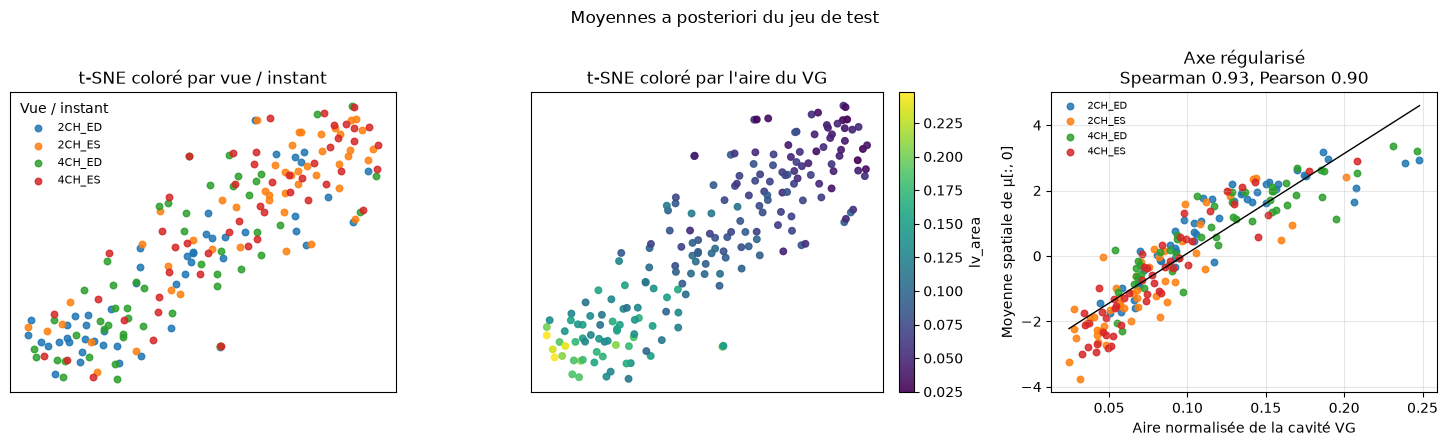

In [15]:
mu_np = test_pred["mu"].numpy()
flat = mu_np.reshape(mu_np.shape[0], -1)
print(f"Matrice passée à t-SNE : {flat.shape} = (images de test, coefficients latents).")
embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED,
).fit_transform(flat)
print(f"Projection t-SNE : {embedding.shape}")

z0 = test_pred["mu"][:, 0].mean(dim=(1, 2)).numpy()
lv_area = np.asarray(test_pred["lv_area"], dtype=np.float64)
spearman_rho, spearman_p = spearmanr(z0, lv_area)
pearson_r, pearson_p = pearsonr(z0, lv_area)
print(f"Spearman(z0, lv_area) = {spearman_rho:.3f}  (p = {spearman_p:.3g})")
print(f"Pearson(z0, lv_area)  = {pearson_r:.3f}  (p = {pearson_p:.3g})")

within_view = {}
for view in ("2CH", "4CH"):
    selected = test_pred["view"] == view
    rho, p_value = spearmanr(z0[selected], lv_area[selected])
    within_view[view] = {
        "spearman": float(rho),
        "pvalue": float(p_value),
        "n": int(selected.sum()),
    }
    print(f"Spearman dans la vue {view} (n = {int(selected.sum())}) : {rho:.3f}  (p = {p_value:.3g})")

column_exp5["spearman"] = float(spearman_rho)
epi_area = np.asarray(test_pred["epi_area"], dtype=np.float64)
la_area = np.asarray(test_pred["la_area"], dtype=np.float64)
attribute_stats = {}
attribute_rows = []
for attribute_name, attribute_values in (
    ("lv_area", lv_area),
    ("epi_area", epi_area),
    ("la_area", la_area),
):
    attribute_rho, attribute_p = spearmanr(z0, attribute_values)
    attribute_stats[attribute_name] = {
        "spearman": float(attribute_rho),
        "pvalue": float(attribute_p),
    }
    attribute_rows.append([attribute_name, f"{attribute_rho:.3f}", f"{attribute_p:.3g}"])
    print(f"Spearman(z0, {attribute_name}) = {attribute_rho:.3f}  (p = {attribute_p:.3g})")
display(Markdown(
    "### Spearman de z0 par attribut\n\n"
    + markdown_table(["Attribut", "Spearman", "p"], attribute_rows)
))
spearman_displays = []
spearman_values = []
for column in ordered:
    if column["spearman"] is None:
        spearman_displays.append("n.d.")
        spearman_values.append(None)
    else:
        spearman_displays.append(f"{column['spearman']:.3f}")
        spearman_values.append(column["spearman"])
spearman_row = ["Spearman(z0, aire VG)", *mark_best(spearman_displays, spearman_values, higher=True)]
display(Markdown(
    "### Spearman de l'axe régularisé\n\n"
    + markdown_table(headers, table_rows + [spearman_row])
))

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.5))
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[0].scatter(
        embedding[selected, 0],
        embedding[selected, 1],
        s=22,
        alpha=0.85,
        label=view_instant,
    )
axes[0].legend(frameon=False, title="Vue / instant", fontsize=8)
axes[0].set_title("t-SNE coloré par vue / instant")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].grid(True, color="0.9")

area_scatter = axes[1].scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=lv_area,
    cmap="viridis",
    s=22,
    alpha=0.9,
)
axes[1].set_title("t-SNE coloré par l'aire du VG")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].grid(True, color="0.9")
fig.colorbar(area_scatter, ax=axes[1], fraction=0.046, pad=0.04, label="lv_area")

for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[2].scatter(lv_area[selected], z0[selected], s=22, alpha=0.85, label=view_instant)
order = np.argsort(lv_area)
slope, intercept = np.polyfit(lv_area, z0, 1)
axes[2].plot(lv_area[order], slope * lv_area[order] + intercept, color="black", lw=1.0)
axes[2].set_xlabel("Aire normalisée de la cavité VG")
axes[2].set_ylabel("Moyenne spatiale de μ[:, 0]")
axes[2].set_title(f"Axe régularisé\nSpearman {spearman_rho:.2f}, Pearson {pearson_r:.2f}")
axes[2].grid(True, alpha=0.3)
axes[2].legend(frameon=False, fontsize=7)
fig.suptitle("Moyennes a posteriori du jeu de test")
fig.tight_layout()
plt.show()


### Interpolation ED → ES

Le trajet relie la moyenne a posteriori de la télédiastole à celle de la télésystole pour `patient0010` en vue 4CH, les deux cadres étant dans le test. Le GIF fait l'aller puis le retour.


patient0010 4CH : interpolation de μ_ED vers μ_ES, 16 pas.
GIF aller-retour enregistré dans artifacts\exp5_interp_ED_ES.gif.


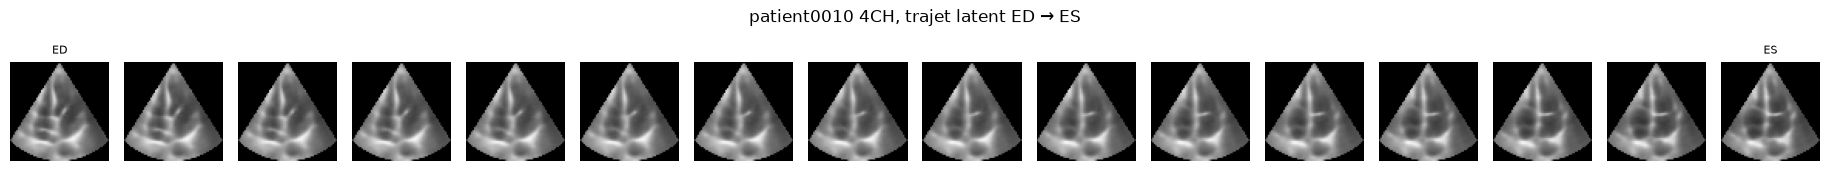

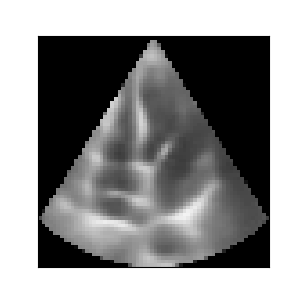

In [16]:
def pair_index(dataset):
    pairs = {}
    for index, record in enumerate(dataset.records):
        pairs.setdefault((record["patient"], record["view"]), {})[record["instant"]] = index
    return pairs


def encode_mu(model, dataset, index):
    image = dataset[index]["image"][None].to(device, non_blocking=True)
    with torch.no_grad():
        mu, _ = model.encode(image)
    return mu


def interpolate(model, z_start, z_end, steps):
    weights = torch.linspace(0, 1, steps, device=z_start.device)
    codes = torch.cat([torch.lerp(z_start, z_end, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = decode_image(model, codes)[:, 0].cpu().numpy()
    return frames


def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)
    return animation


pairs = pair_index(test_dataset)
gif_key = ("patient0010", "4CH")
if gif_key not in pairs or not {"ED", "ES"} <= set(pairs[gif_key]):
    raise RuntimeError(f"Paire ED/ES introuvable pour {gif_key} dans le test.")
ed_index = pairs[gif_key]["ED"]
es_index = pairs[gif_key]["ES"]
gif_patient, gif_view = gif_key

z_ed = encode_mu(model, test_dataset, ed_index)
z_es = encode_mu(model, test_dataset, es_index)
forward = interpolate(model, z_ed, z_es, steps=16)
cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)

gif_path = ARTIFACT_DIR / "exp5_interp_ED_ES.gif"
save_gif(cycle, gif_path, fps=8)
print(f"{gif_patient} {gif_view} : interpolation de μ_ED vers μ_ES, {forward.shape[0]} pas.")
print(f"GIF aller-retour enregistré dans {gif_path}.")

fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
for ax, frame in zip(axes, forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("ED", fontsize=8)
axes[-1].set_title("ES", fontsize=8)
fig.suptitle(f"{gif_patient} {gif_view}, trajet latent ED → ES")
fig.tight_layout()
plt.show()

display(Image(filename=str(gif_path)))


### Balayage de l'axe latent régularisé

Le GIF part d'un cadre de test dont l'aire de cavité est médiane. Seule la moyenne spatiale du canal 0 de μ est déplacée, du 5e au 95e percentile de `z0` sur le test, puis le trajet revient. Les autres coefficients restent ceux de l'image d'origine.


Balayage de z0 sur patient0272 4CH_ES : -2.506 → 2.592, 16 pas.
GIF de balayage enregistré dans artifacts\exp5_latent_sweep.gif.


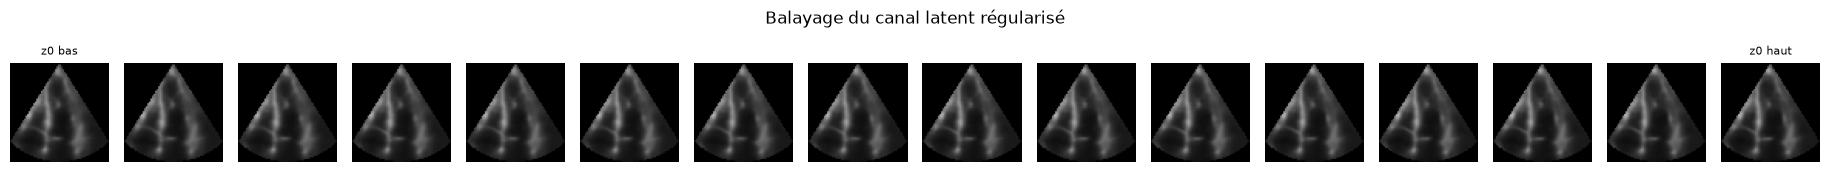

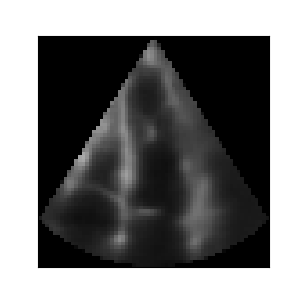

In [17]:
z0_test = test_pred["mu"][:, 0].mean(dim=(1, 2))
median_order = np.argsort(test_pred["lv_area"])
sweep_index = int(median_order[len(median_order) // 2])
base_mu = test_pred["mu"][sweep_index:sweep_index + 1].to(device)
base_z0 = base_mu[:, 0].mean()
low = torch.quantile(z0_test.to(device), 0.05)
high = torch.quantile(z0_test.to(device), 0.95)
targets = torch.linspace(float(low), float(high), 16, device=device)
sweep_frames = []
with torch.no_grad():
    for target in targets:
        shifted = base_mu.clone()
        shifted[:, 0] = shifted[:, 0] + (target - base_z0)
        sweep_frames.append(decode_image(model, shifted)[0, 0].cpu().numpy())
sweep_forward = np.stack(sweep_frames, axis=0)
sweep_cycle = np.concatenate([sweep_forward, sweep_forward[-2:0:-1]], axis=0)
sweep_gif_path = ARTIFACT_DIR / "exp5_latent_sweep.gif"
save_gif(sweep_cycle, sweep_gif_path, fps=8)
print(
    f"Balayage de z0 sur {test_pred['patient'][sweep_index]} "
    f"{test_pred['view_instant'][sweep_index]} : "
    f"{float(low):.3f} → {float(high):.3f}, {sweep_forward.shape[0]} pas."
)
print(f"GIF de balayage enregistré dans {sweep_gif_path}.")

fig, axes = plt.subplots(1, sweep_forward.shape[0], figsize=(1.15 * sweep_forward.shape[0], 1.8))
for ax, frame in zip(axes, sweep_forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("z0 bas", fontsize=8)
axes[-1].set_title("z0 haut", fontsize=8)
fig.suptitle("Balayage du canal latent régularisé")
fig.tight_layout()
plt.show()
display(Image(filename=str(sweep_gif_path)))


In [18]:
results_exp5 = {
    "experiment": 5,
    "seed": SEED,
    "device": str(device),
    "gpu": gpu_name,
    "vram_bytes": int(vram_total),
    "torch": torch.__version__,
    "monai": monai.__version__,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_loss": CONFIG["recon_loss"],
    "heart_weight_map": "1 + 3.5 * (label > 0)",
    "attribute": "spatial mean of mu[:, 0] ranked with lv cavity area, label == 1",
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "num_res_blocks": NUM_RES_BLOCKS,
    "latent_shape": list(LATENT_SHAPE),
    "n_params": N_PARAMS,
    "optimizer": "AdamW",
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "precision": "fp32",
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "best_val_recon": history["best_val"],
    "seconds": history["seconds"],
    "seconds_per_epoch": history["seconds"] / history["epochs"],
    "max_memory_mb": history.get("max_memory_mb"),
    "history": {
        key: value
        for key, value in history.items()
        if key != "config"
    },
    "test": {
        "n": len(test_dataset),
        "mse_mean": exp5_mse,
        "mse_std": exp5_mse_std,
        "mae_mean": exp5_mae,
        "mae_std": exp5_mae_std,
        "psnr_mean": exp5_psnr,
        "psnr_std": exp5_psnr_std,
        "ssim_mean": exp5_ssim,
        "ssim_std": exp5_ssim_std,
        "heart_mse_mean": exp5_heart,
        "heart_mse_std": exp5_heart_std,
        "heart_psnr_mean": exp5_heart_psnr,
        "heart_psnr_std": exp5_heart_psnr_std,
        "background_mse_mean": exp5_background,
        "background_mse_std": exp5_background_std,
        "per_view_instant": per_view_instant,
    },
    "latent_attribute": {
        "spearman_mu0_lv_area": float(spearman_rho),
        "spearman_pvalue": float(spearman_p),
        "pearson_mu0_lv_area": float(pearson_r),
        "pearson_pvalue": float(pearson_p),
        "by_attribute": attribute_stats,
        "within_view": within_view,
        "n": int(len(z0)),
    },
    "interpolation_gif": str(gif_path),
    "latent_sweep_gif": str(sweep_gif_path),
    "comparison": comparison_columns,
}

exp4_reference = {
    "mse": column_exp4["mse"],
    "heart_mse": column_exp4["heart_mse"],
    "ssim": column_exp4["ssim"],
    "psnr": column_exp4["psnr"],
}
fidelity_checks = {
    "MSE < expérience 4": exp5_mse < exp4_reference["mse"],
    "MSE cœur < expérience 4": exp5_heart < exp4_reference["heart_mse"],
    "SSIM > expérience 4": exp5_ssim > exp4_reference["ssim"],
    "PSNR > expérience 4": exp5_psnr > exp4_reference["psnr"],
    "Spearman > 0.85": float(spearman_rho) > 0.85,
}
results_exp5["fidelity_checks"] = fidelity_checks
results_exp5["experiment_4_reference"] = exp4_reference

results_path = ARTIFACT_DIR / "results_exp5.json"
results_path.write_text(
    json.dumps(results_exp5, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)


def checklist(title, checks):
    lines = [f"### {title}", ""]
    for label, passed in checks.items():
        mark = "oui" if passed else "non"
        lines.append(f"- {label} : {mark}")
    return "\n".join(lines)


def signed(value, digits):
    return f"{value:+.{digits}f}"


latent_text = "×".join(str(value) for value in LATENT_SHAPE)
synthesis = "\n".join([
    "## Synthèse",
    "",
    (
        f"L'expérience 5 entraîne {fmt_int(N_PARAMS)} paramètres, canaux {tuple(CHANNELS)}, "
        f"attention au dernier niveau, code latent {latent_text}, pendant {history['epochs']} époques "
        f"sur {gpu_name}. Le checkpoint retenu est l'époque {history['best_epoch']}, "
        f"la plus faible reconstruction de validation après le warmup "
        f"({history['best_val']:.5f}). La boucle dure {history['seconds'] / 60:.2f} min, "
        f"soit {history['seconds'] / history['epochs']:.2f} s par époque. "
        f"Le pic de VRAM mesuré pendant cette boucle est {history.get('max_memory_mb', float('nan')):.0f} Mo."
    ),
    "",
    (
        f"Sur les 200 images de test, la MSE vaut {exp5_mse:.5f}, le PSNR {exp5_psnr:.2f} dB, "
        f"le SSIM {exp5_ssim:.3f} et la MAE {exp5_mae:.3f}. "
        f"Par rapport à l'expérience 4 (MSE {exp4_reference['mse']:.5f}, "
        f"PSNR {exp4_reference['psnr']:.2f} dB, SSIM {exp4_reference['ssim']:.3f}), "
        f"l'écart de MSE est {signed(exp5_mse - exp4_reference['mse'], 5)}, "
        f"l'écart de PSNR est {signed(exp5_psnr - exp4_reference['psnr'], 2)} dB "
        f"et l'écart de SSIM est {signed(exp5_ssim - exp4_reference['ssim'], 3)}."
    ),
    "",
    (
        f"La MSE sur le cœur vaut {exp5_heart:.5f} "
        f"(expérience 4 : {exp4_reference['heart_mse']:.5f}, écart "
        f"{signed(exp5_heart - exp4_reference['heart_mse'], 5)}). "
        f"Le PSNR dans le masque cardiaque vaut {exp5_heart_psnr:.2f} dB. "
        f"La MSE de fond vaut {exp5_background:.5f}. "
        f"Le poids W = 1 + {HEART_WEIGHT:.1f} sur les pixels de cœur, "
        "et le terme de gradient pousse les différences finies des parois."
    ),
    "",
    (
        f"Spearman(z0, aire du VG) = {spearman_rho:.3f} (p = {spearman_p:.3g}), Pearson = {pearson_r:.3f}. "
        f"Spearman(z0, aire épicardique) = {attribute_stats['epi_area']['spearman']:.3f}, "
        f"Spearman(z0, aire de l'oreillette) = {attribute_stats['la_area']['spearman']:.3f}. "
        f"Seul l'axe de la cavité est dans la perte, avec γ = {GAMMA:.2f} et β max = {BETA_MAX:.0e}. "
        f"À l'intérieur de chaque vue, Spearman 2CH = {within_view['2CH']['spearman']:.3f} et "
        f"Spearman 4CH = {within_view['4CH']['spearman']:.3f}."
    ),
    "",
    (
        "Le calcul est resté en FP32, sans TF32. Les tenseurs d'entraînement et de validation "
        "étaient en VRAM avant la première époque, et les moyennes de perte n'ont été lues "
        "sur le CPU qu'une fois par époque. Le fichier de poids n'a été écrit qu'à la fin."
    ),
    "",
    checklist("Dépassement de l'expérience 4", fidelity_checks),
])
display(Markdown(synthesis))
print(f"Résultats écrits dans {results_path}.")
print(
    f"Expérience 5 — meilleure époque {history['best_epoch']}/{history['epochs']}, "
    f"MSE test {exp5_mse:.5f}, PSNR {exp5_psnr:.2f} dB, "
    f"SSIM {exp5_ssim:.3f}, MSE cœur {exp5_heart:.5f}, "
    f"PSNR cœur {exp5_heart_psnr:.2f} dB, "
    f"Spearman {spearman_rho:.3f}, durée {history['seconds'] / 60:.2f} min."
)

quality_failed = [label for label, passed in fidelity_checks.items() if not passed]
if quality_failed:
    raise AssertionError("Barre de fidélité manquée : " + ", ".join(quality_failed))


## Synthèse

L'expérience 5 entraîne 8 233 153 paramètres, canaux (32, 64, 128, 256), attention au dernier niveau, code latent 8×8×8, pendant 100 époques sur NVIDIA GeForce RTX 4060 Ti. Le checkpoint retenu est l'époque 48, la plus faible reconstruction de validation après le warmup (0.06131). La boucle dure 6.30 min, soit 3.78 s par époque. Le pic de VRAM mesuré pendant cette boucle est 2997 Mo.

Sur les 200 images de test, la MSE vaut 0.00268, le PSNR 26.04 dB, le SSIM 0.808 et la MAE 0.028. Par rapport à l'expérience 4 (MSE 0.00343, PSNR 25.12 dB, SSIM 0.787), l'écart de MSE est -0.00075, l'écart de PSNR est +0.92 dB et l'écart de SSIM est +0.021.

La MSE sur le cœur vaut 0.00446 (expérience 4 : 0.00518, écart -0.00072). Le PSNR dans le masque cardiaque vaut 23.73 dB. La MSE de fond vaut 0.00212. Le poids W = 1 + 3.5 sur les pixels de cœur, et le terme de gradient pousse les différences finies des parois.

Spearman(z0, aire du VG) = 0.933 (p = 3.93e-90), Pearson = 0.900. Spearman(z0, aire épicardique) = 0.882, Spearman(z0, aire de l'oreillette) = -0.221. Seul l'axe de la cavité est dans la perte, avec γ = 0.03 et β max = 2e-05. À l'intérieur de chaque vue, Spearman 2CH = 0.932 et Spearman 4CH = 0.933.

Le calcul est resté en FP32, sans TF32. Les tenseurs d'entraînement et de validation étaient en VRAM avant la première époque, et les moyennes de perte n'ont été lues sur le CPU qu'une fois par époque. Le fichier de poids n'a été écrit qu'à la fin.

### Dépassement de l'expérience 4

- MSE < expérience 4 : oui
- MSE cœur < expérience 4 : oui
- SSIM > expérience 4 : oui
- PSNR > expérience 4 : oui
- Spearman > 0.85 : oui

Résultats écrits dans artifacts\results_exp5.json.
Expérience 5 — meilleure époque 48/100, MSE test 0.00268, PSNR 26.04 dB, SSIM 0.808, MSE cœur 0.00446, PSNR cœur 23.73 dB, Spearman 0.933, durée 6.30 min.
